In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import seaborn as sns
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
from keras.layers import Dense, Input, Dropout, BatchNormalization
from keras.models import Sequential 
import matplotlib.pyplot as plt

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/adult-census-income/adult.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/uciml/adult-census-income/adult.csv')

#preprocessing

df['income'] = np.where(df['income']=='<=50K',0,1)
df['occupation'] = df['occupation'].replace('?', 'Missinng')
df['workclass'] = df['workclass'].replace('?', 'Missinng')

columns=['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']

ohe = OneHotEncoder(sparse_output=False)
xd = ohe.fit_transform(df[columns])

column_names = ohe.get_feature_names_out()
df[column_names] = xd

df = df.drop(columns=columns)

df.head()

/tmp/ipykernel_16/3670100514.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[column_names] = xd
/tmp/ipykernel_16/3670100514.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[column_names] = xd
/tmp/ipykernel_16/3670100514.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[column_n

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,income,workclass_Federal-gov,workclass_Local-gov,workclass_Missinng,...,native.country_Portugal,native.country_Puerto-Rico,native.country_Scotland,native.country_South,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia
0,90,77053,9,0,4356,40,0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,82,132870,9,0,4356,18,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,66,186061,10,0,4356,40,0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,54,140359,4,0,3900,40,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,41,264663,10,0,3900,40,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


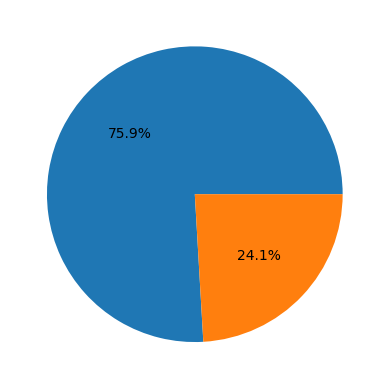

In [3]:
y = df['income']
x = df.drop('income', axis=1)

x = x.astype('float32')
y = y.astype('float32')

x_scaler = StandardScaler()
x_scaled = x_scaler.fit_transform(x)

vc = df['income'].value_counts()
plt.pie(vc.values, autopct='%1.1f%%')
plt.show()

In [4]:
x_train,x_test,y_train,y_test = train_test_split(
    x_scaled,y,random_state=42,train_size=0.77,stratify=y
)

model = Sequential()

model.add(Input(shape=(x_train.shape[1],)))
model.add(Dense(64, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.3)) 

model.add(Dense(32, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

class_weights = {0: 1.0, 1: 1.5}

model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=128,
    class_weight=class_weights,
    validation_data=(x_test, y_test)
)

2026-09-26 20:36:53.284346: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7369 - loss: 0.6038 - val_accuracy: 0.8188 - val_loss: 0.3906
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8192 - loss: 0.4688 - val_accuracy: 0.8327 - val_loss: 0.3603
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8308 - loss: 0.4389 - val_accuracy: 0.8348 - val_loss: 0.3501
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8339 - loss: 0.4287 - val_accuracy: 0.8377 - val_loss: 0.3424
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8343 - loss: 0.4210 - val_accuracy: 0.8339 - val_loss: 0.3439
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8373 - loss: 0.4175 - val_accuracy: 0.8422 - val_loss: 0.3367
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8385 - loss: 0.4105 - val_accuracy: 0.8398 - val_loss: 0.3375
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8420 - loss: 0.4032 - val_accuracy: 0.

In [5]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(test_acc)

235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8405 - loss: 0.3307
0.8404539227485657


235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


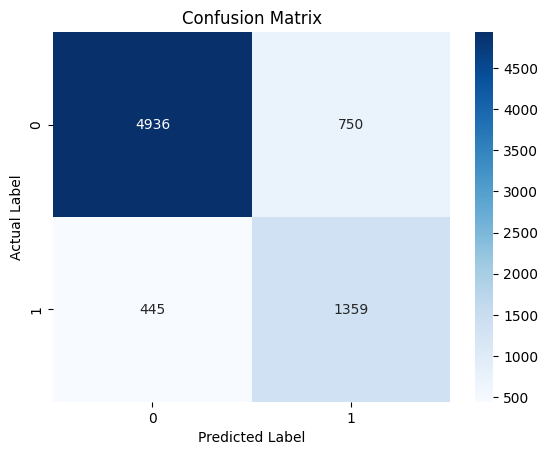

In [6]:
y_pred_probs = model.predict(x_test)
y_pred = (y_pred_probs >= 0.50).astype(int)

sns.heatmap(confusion_matrix(y_test, y_pred), cmap='Blues', annot=True, fmt='d')

plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label') 

plt.show()